In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("waddahali/fraud-detection")

print("Path to dataset files:", path)

100%|██████████| 321k/321k [00:00<00:00, 1.16MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/waddahali/fraud-detection/versions/1


In [2]:
import os

print(os.listdir(path))

['fraud.csv']


In [4]:
import pandas as pd
import os
file_path = os.path.join(path,"fraud.csv")
df=pd.read_csv(file_path)
print("DATASET LOADED")

DATASET LOADED


In [5]:
df.head()

,transaction_amount,hour_of_day,is_weekend,num_items,customer_age,prev_transactions,distance_from_home,device_type,network_quality,is_first_transaction,store_type,velocity_score,is_fraud
0,161.363691,3.0,0.0,2.0,18.000000,2.0,26.539742,1.0,48.403937,0.0,0.0,3.718296,0
1,116.202851,1.0,1.0,4.0,26.285818,2.0,50.714402,NaN,76.144979,0.0,0.0,4.951272,0
2,1.000000,2.0,0.0,5.0,18.000000,NaN,9.467935,0.0,67.600316,0.0,0.0,4.556043,0
3,48.780618,2.0,0.0,3.0,44.471190,NaN,41.077068,0.0,94.825526,0.0,0.0,6.918437,0
4,NaN,3.0,0.0,4.0,38.733609,8.0,NaN,2.0,100.000000,0.0,1.0,5.535335,1


In [7]:
df.shape

(7000, 13)

In [9]:
df.columns

Index(['transaction_amount', 'hour_of_day', 'is_weekend', 'num_items',
       'customer_age', 'prev_transactions', 'distance_from_home',
       'device_type', 'network_quality', 'is_first_transaction', 'store_type',
       'velocity_score', 'is_fraud'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   transaction_amount    6440 non-null   float64
 1   hour_of_day           6650 non-null   float64
 2   is_weekend            6860 non-null   float64
 3   num_items             6790 non-null   float64
 4   customer_age          6160 non-null   float64
 5   prev_transactions     6510 non-null   float64
 6   distance_from_home    6300 non-null   float64
 7   device_type           6720 non-null   float64
 8   network_quality       6370 non-null   float64
 9   is_first_transaction  6790 non-null   float64
 10  store_type            6860 non-null   float64
 11  velocity_score        5950 non-null   float64
 12  is_fraud              7000 non-null   int64  
dtypes: float64(12), int64(1)
memory usage: 711.1 KB


In [12]:
df.isnull().sum()

,0
transaction_amount,560
hour_of_day,350
is_weekend,140
num_items,210
customer_age,840
prev_transactions,490
distance_from_home,700
device_type,280
network_quality,630
is_first_transaction,210


In [13]:
missing_percentage=(df.isnull().sum()/len(df))*100
print(missing_percentage)

transaction_amount       8.0
hour_of_day              5.0
is_weekend               2.0
num_items                3.0
customer_age            12.0
prev_transactions        7.0
distance_from_home      10.0
device_type              4.0
network_quality          9.0
is_first_transaction     3.0
store_type               2.0
velocity_score          15.0
is_fraud                 0.0
dtype: float64


In [14]:
df.describe()

,transaction_amount,hour_of_day,is_weekend,num_items,customer_age,prev_transactions,distance_from_home,device_type,network_quality,is_first_transaction,store_type,velocity_score,is_fraud
count,6440.000000,6650.000000,6860.000000,6790.000000,6160.000000,6510.000000,6300.000000,6720.000000,6370.000000,6790.000000,6860.000000,5950.000000,7000.000000
mean,100.014648,2.200902,0.108601,2.977320,36.200811,4.457604,24.830735,0.698810,74.094739,0.095876,0.286735,5.007450,0.103000
std,49.091009,0.677906,0.311160,1.712444,13.283996,4.881635,24.314751,0.776802,18.003855,0.294443,0.452270,2.007633,0.303981
min,1.000000,1.000000,0.000000,0.000000,18.000000,0.000000,0.004282,0.000000,0.477174,0.000000,0.000000,-1.853966,0.000000
25%,65.711569,2.000000,0.000000,2.000000,25.244168,1.000000,7.387315,0.000000,61.586731,0.000000,0.000000,3.697990,0.000000
50%,99.482201,2.000000,0.000000,3.000000,35.361187,3.000000,17.321496,1.000000,75.306346,0.000000,0.000000,4.992099,0.000000
75%,132.897923,3.000000,0.000000,4.000000,45.500089,6.000000,34.857859,1.000000,88.253574,0.000000,1.000000,6.342852,0.000000
max,296.311885,3.000000,1.000000,13.000000,80.000000,40.000000,224.699757,2.000000,100.000000,1.000000,1.000000,12.659564,1.000000


In [15]:
columns_to_check = [
    'hour_of_day',
    'is_weekend',
    'device_type',
    'is_first_transaction',
    'store_type',
    'is_fraud'
]

for col in columns_to_check:
    print(col, ":", sorted(df[col].dropna().unique()))

hour_of_day : [np.float64(1.0), np.float64(2.0), np.float64(3.0)]
is_weekend : [np.float64(0.0), np.float64(1.0)]
device_type : [np.float64(0.0), np.float64(1.0), np.float64(2.0)]
is_first_transaction : [np.float64(0.0), np.float64(1.0)]
store_type : [np.float64(0.0), np.float64(1.0)]
is_fraud : [np.int64(0), np.int64(1)]


Handle Missing Values

replaces missing ages with that median

In [17]:
numerical_cols=['transaction_amount','num_items','customer_age','prev_transactions','distance_from_home','network_quality','velocity_score']
for col in numerical_cols:
  df[col]=df[col].fillna(df[col].median())

finds the most frequently occurring value.

In [18]:
categorical_cols = ['hour_of_day','is_weekend','device_type','is_first_transaction','store_type']
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [19]:
df.isnull().sum()

,0
transaction_amount,0
hour_of_day,0
is_weekend,0
num_items,0
customer_age,0
prev_transactions,0
distance_from_home,0
device_type,0
network_quality,0
is_first_transaction,0


Check for duplicate records

In [20]:
df.duplicated().sum()

np.int64(0)

Feature Selection

In [21]:
X=df.drop('is_fraud',axis=1)
Y=df['is_fraud']
print("features shape:",X.shape)
print("target shape:",Y.shape)

features shape: (7000, 12)
target shape: (7000,)


Categorical Encoding

In [22]:
print(X.columns.tolist())

['transaction_amount', 'hour_of_day', 'is_weekend', 'num_items', 'customer_age', 'prev_transactions', 'distance_from_home', 'device_type', 'network_quality', 'is_first_transaction', 'store_type', 'velocity_score']


In [25]:
X_encoded=pd.get_dummies(X,columns=['hour_of_day','device_type'],dtype=int)
print("original shape:",X.shape)
print("encoded shape:",X_encoded.shape)
print(X_encoded.head())

original shape: (7000, 12)
encoded shape: (7000, 16)
   transaction_amount  is_weekend  num_items  customer_age  prev_transactions  \
0          161.363691         0.0        2.0     18.000000                2.0   
1          116.202851         1.0        4.0     26.285818                2.0   
2            1.000000         0.0        5.0     18.000000                3.0   
3           48.780618         0.0        3.0     44.471190                3.0   
4           99.482201         0.0        4.0     38.733609                8.0   

   distance_from_home  network_quality  is_first_transaction  store_type  \
0           26.539742        48.403937                   0.0         0.0   
1           50.714402        76.144979                   0.0         0.0   
2            9.467935        67.600316                   0.0         0.0   
3           41.077068        94.825526                   0.0         0.0   
4           17.321496       100.000000                   0.0         1.0   

   

Normalization

In [26]:
from sklearn.preprocessing import StandardScaler

In [27]:
numerical_cols=['transaction_amount','num_items','customer_age','prev_transactions','distance_from_home','network_quality','velocity_score']

In [28]:
scaler=StandardScaler()

In [31]:
X_encoded[numerical_cols]=scaler.fit_transform(X_encoded[numerical_cols])

In [32]:
X_encoded[numerical_cols].describe().loc[['mean','std']]

,transaction_amount,num_items,customer_age,prev_transactions,distance_from_home,network_quality,velocity_score
mean,-4.060244e-17,-1.400784e-16,-1.096266e-16,2.689912e-17,4.567775e-17,3.177141e-16,1.735754e-16
std,1.000071e+00,1.000071e+00,1.000071e+00,1.000071e+00,1.000071e+00,1.000071e+00,1.000071e+00


Exploratory Data Analysis (EDA)

In [34]:
print(df['is_fraud'].value_counts())

is_fraud
0    6279
1     721
Name: count, dtype: int64


In [35]:
print(df['is_fraud'].value_counts(normalize=True) * 100)

is_fraud
0    89.7
1    10.3
Name: proportion, dtype: float64


Visualize the target distribution

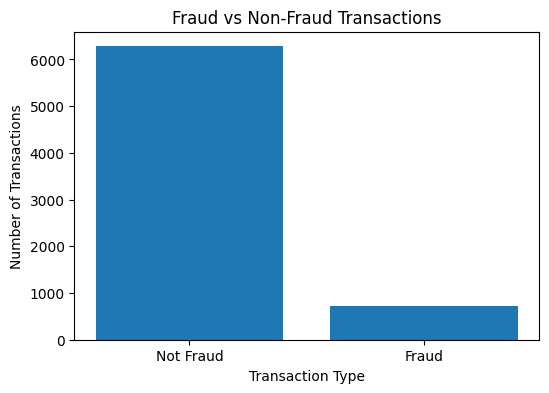

In [36]:
import matplotlib.pyplot as plt
fraud_counts = df['is_fraud'].value_counts()
plt.figure(figsize=(6, 4))
plt.bar(['Not Fraud', 'Fraud'], fraud_counts.values)
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')
plt.title('Fraud vs Non-Fraud Transactions')
plt.show()

Compare transaction amount for fraud vs. non-fraud

/tmp/ipykernel_1690/1919805312.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


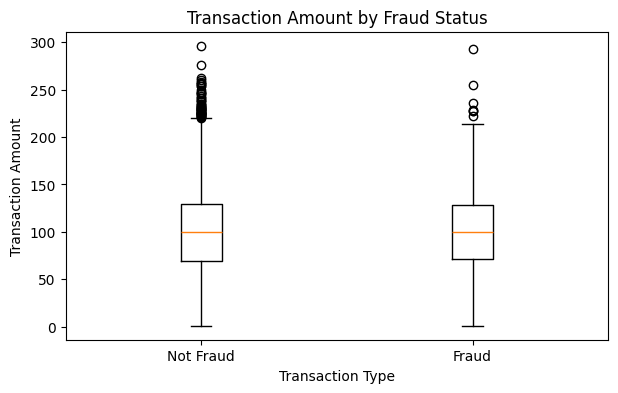

In [37]:
plt.figure(figsize=(7, 4))

plt.boxplot(
    [
        df[df['is_fraud'] == 0]['transaction_amount'],
        df[df['is_fraud'] == 1]['transaction_amount']
    ],
    labels=['Not Fraud', 'Fraud']
)

plt.xlabel('Transaction Type')
plt.ylabel('Transaction Amount')
plt.title('Transaction Amount by Fraud Status')
plt.show()

In [38]:
df.groupby('is_fraud')['transaction_amount'].mean()

,transaction_amount
is_fraud,
0,99.781577
1,101.630855


In [40]:
final_df = X_encoded.copy()

final_df['is_fraud'] = Y.values

print("Final dataset shape:", final_df.shape)
print(final_df.head())

Final dataset shape: (7000, 17)
   transaction_amount  is_weekend  num_items  customer_age  prev_transactions  \
0            1.303902         0.0  -0.579919     -1.452249          -0.498852   
1            0.344727         1.0   0.606009     -0.787440          -0.498852   
2           -2.102076         0.0   1.198974     -1.452249          -0.287077   
3           -1.087259         0.0   0.013045      0.671654          -0.287077   
4           -0.010404         0.0   0.606009      0.211302           0.771800   

   distance_from_home  network_quality  is_first_transaction  store_type  \
0            0.106146        -1.502023                   0.0         0.0   
1            1.149285         0.113013                   0.0         0.0   
2           -0.630504        -0.384443                   0.0         0.0   
3            0.733433         1.200562                   0.0         0.0   
4           -0.291622         1.501811                   0.0         1.0   

   velocity_score  hour_

In [41]:
final_df.to_csv('fraud_preprocessed.csv', index=False)

print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!


In [42]:
print("Missing values:")
print(final_df.isnull().sum().sum())

print("\nDuplicate rows:")
print(final_df.duplicated().sum())

Missing values:
0

Duplicate rows:
0
